# Challenge 4

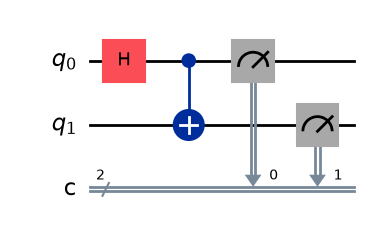

In [1]:

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Part A: Correlated outcomes
qc_a = QuantumCircuit(2, 2)

qc_a.h(0)
qc_a.cx(0, 1)

qc_a.measure([0, 1], [0, 1])

qc_a.draw("mpl")

In [2]:

simulator = AerSimulator()

result_a = simulator.run(qc_a, shots=100).result()
counts_a = result_a.get_counts()

print("Part A results:", counts_a)
print("Total shots:", sum(counts_a.values()))

Part A results: {'11': 55, '00': 45}
Total shots: 100


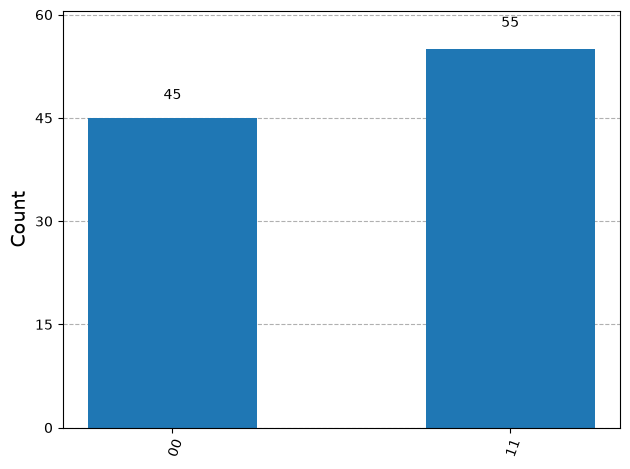

In [3]:

plot_histogram(counts_a)

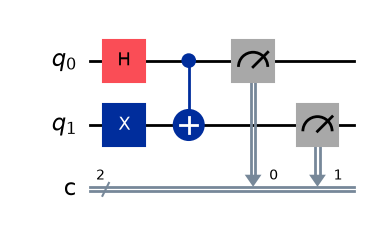

In [4]:

# Part B: Opposite outcomes
qc_b = QuantumCircuit(2, 2)

qc_b.x(1)
qc_b.h(0)
qc_b.cx(0, 1)

qc_b.measure([0, 1], [0, 1])

qc_b.draw("mpl")

In [5]:

result_b = simulator.run(qc_b, shots=100).result()
counts_b = result_b.get_counts()

print("Part B results:", counts_b)
print("Total shots:", sum(counts_b.values()))

Part B results: {'10': 45, '01': 55}
Total shots: 100


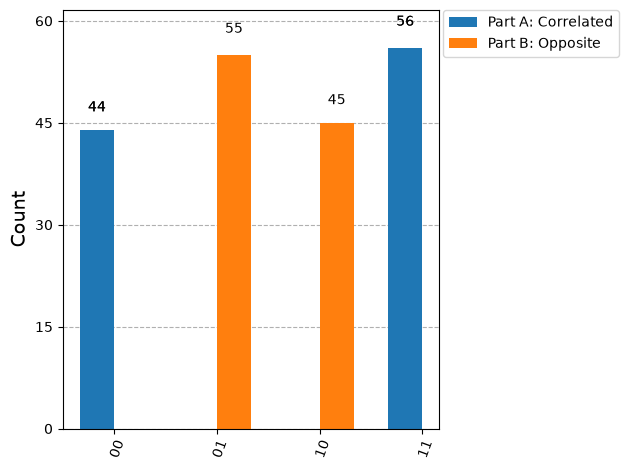

In [6]:

plot_histogram(
    [counts_a, counts_b],
    legend=["Part A: Correlated", "Part B: Opposite"]
)

### Predictions

**Part A — Correlated outcomes:** I predict that `00` and `11` will each occur approximately 50% of the time. The outcomes should be the same for both qubits.

**Part B — Opposite outcomes:** I predict that `01` and `10` will each occur approximately 50% of the time. The outcomes should be different for the two qubits.

### Comparison and Observations

In Part A, the dominant outcomes are `00` and `11`, indicating correlated measurement results. In Part B, the dominant outcomes are `01` and `10`, indicating opposite measurement results.

The main change is the addition of an X gate on qubit 1 in Part B. This gate flips that qubit from \(|0\rangle\) to \(|1\rangle\) before the Hadamard and CNOT operations. As a result, the final quantum state changes from \((|00\rangle+|11\rangle)/\sqrt{2}\) to \((|01\rangle+|10\rangle)/\sqrt{2}\).

Ideally, the other two outcomes are not observed in either circuit. Small differences in the counts between the two dominant outcomes are expected because measurement is probabilistic. In an ideal simulator, only the two expected outcomes have nonzero probability.
